### Step 2: SNAP units decision
**Decision:** Analyze SNAP at the source's reporting-unit grain and exclude tribal nations from the county comparison.

**Reason:** The source combines Dodge-Steele-Waseca, Pope-Grant, and six Southwest counties, so county-level SNAP values cannot be reconstructed without extra assumptions. Tribal nations are reported separately from counties and are not assigned to resident counties.

### Step 1: Event-date decision
**Decision:** Use **March 2023** as the Q5 event month.

**Reason:** March was Minnesota's last month with the extra emergency SNAP payment; April was the first regular-benefit-only month. March is the event date for the last extra payment, while April measures the first reduced payment. The descriptive plot will show both sides of the transition.

In [2]:
import pandas as pd
cov = pd.read_parquet("../data/processed/county_covariates.parquet")
print(cov.columns.tolist())
cov.head()

['fips', 'county_name', 'year', 'population', 'households_census', 'poverty_rate', 'child_poverty_rate', 'median_hh_income', 'unemployment_rate', 'pct_no_vehicle', 'senior_poverty_rate', 'pct_senior', 'pct_hh_snap', 'n_sites_reporting', 'sites_per_10k', 'mean_km_to_site']


,fips,county_name,year,population,households_census,poverty_rate,child_poverty_rate,median_hh_income,unemployment_rate,pct_no_vehicle,senior_poverty_rate,pct_senior,pct_hh_snap,n_sites_reporting,sites_per_10k,mean_km_to_site
0,27001,Aitkin,2022,16614,7517,13.5,17.8,59064,4.5,5.178755,10.704009,33.358930,7.650434,5,3.009510,8.368630
1,27001,Aitkin,2023,16104,7533,12.1,16.1,59844,5.1,4.715213,10.467325,33.556448,7.988464,5,3.104819,8.368630
2,27001,Aitkin,2024,16335,7527,13.9,14.5,62351,5.4,4.970922,10.743494,33.998989,8.944891,4,2.448730,11.022783
3,27003,Anoka,2022,368280,136706,7.4,8.1,92249,2.4,4.742912,6.887609,14.543750,6.421609,12,0.325839,3.576531
4,27003,Anoka,2023,371269,138612,6.5,7.6,96661,2.7,4.620661,7.528548,14.904563,6.747398,13,0.350150,3.576531


leakage_check passed: nothing at or after 202608


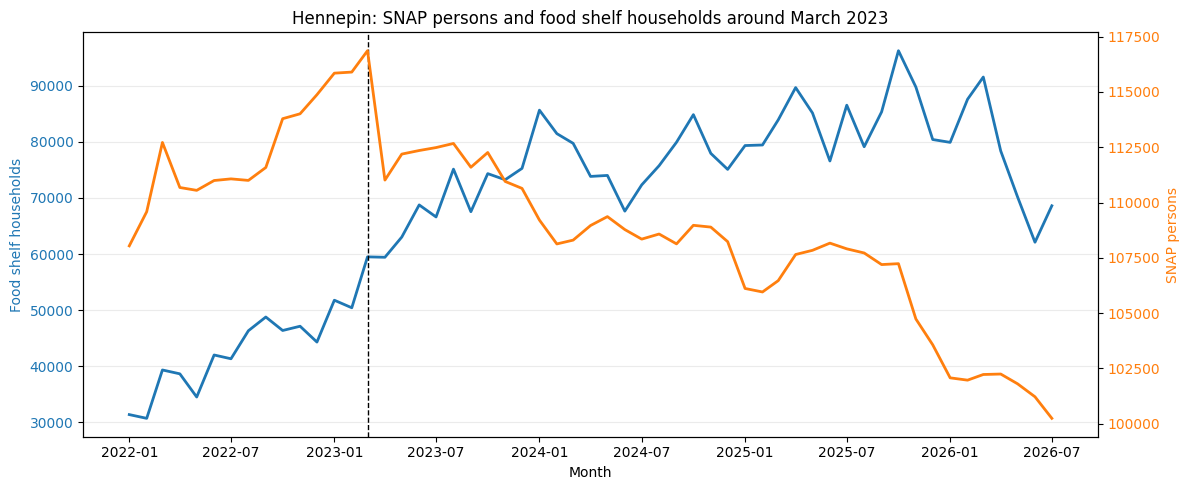

Saved plot to ../outputs/figures/q5_hennepin_snap_vs_food_shelf.png
Pre-event SNAP exposure, March 2022-February 2023:


,snap_unit,mean_snap_persons_pre_event,population_2022,pre_event_snap_participation_percent
10,Cass,4352.58,30821,14.12
70,Traverse,461.33,3346,13.79
56,Ramsey,68483.67,551195,12.42
22,Freeborn,3613.67,30904,11.69
72,Wadena,1639.75,14119,11.61
...,...,...,...,...
12,Chisago,2542.08,59055,4.30
61,Scott,5822.42,154395,3.77
73,Washington,10010.75,274589,3.65
77,Wright,5092.50,150727,3.38


Exposure units: 79


In [3]:
# Step 3: Single-county SNAP and food shelf description; pre-event exposure
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

sys.path.insert(0, "../src")
import qkit

EVENT_MONTH = 202303
PLOT_UNIT = "Hennepin"

snap = qkit.snap(counties_only=True)
activity = qkit.activity_by_snap_unit(food_shelf_only=True)

# Descriptive plot for one county/reporting unit around the March 2023 event.
county_plot = (
    snap.loc[snap["snap_unit"] == PLOT_UNIT, ["date", "yearmonth", "person_count"]]
    .merge(
        activity.loc[
            activity["snap_unit"] == PLOT_UNIT,
            ["yearmonth", "households"],
        ],
        on="yearmonth",
        how="inner",
    )
    .sort_values("date")
)

fig, activity_axis = plt.subplots(figsize=(12, 5))
activity_axis.plot(
    county_plot["date"],
    county_plot["households"],
    color="tab:blue",
    linewidth=2,
    label="Food shelf households",
)
activity_axis.set_ylabel("Food shelf households", color="tab:blue")
activity_axis.tick_params(axis="y", labelcolor="tab:blue")
activity_axis.axvline(
    pd.Timestamp("2023-03-01"),
    color="black",
    linestyle="--",
    linewidth=1,
    label="March 2023 event",
)

snap_axis = activity_axis.twinx()
snap_axis.plot(
    county_plot["date"],
    county_plot["person_count"],
    color="tab:orange",
    linewidth=2,
    label="SNAP persons",
)
snap_axis.set_ylabel("SNAP persons", color="tab:orange")
snap_axis.tick_params(axis="y", labelcolor="tab:orange")

activity_axis.set_title(
    "Hennepin: SNAP persons and food shelf households around March 2023"
)
activity_axis.set_xlabel("Month")
activity_axis.grid(axis="y", alpha=0.25)
fig.tight_layout()
plot_path = "../outputs/figures/q5_hennepin_snap_vs_food_shelf.png"
fig.savefig(plot_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"Saved plot to {plot_path}")

# Pre-event exposure: average SNAP persons in March 2022-February 2023
# divided by 2022 county population, aggregated to the source's SNAP units.
units = qkit.snap_units()
covariates = qkit.covariates(years=[2022]).copy()

population_candidates = [
    "population",
    "total_population",
    "pop",
]
population_column = next(
    column for column in population_candidates if column in covariates.columns
)

unit_population = (
    units[["fips", "snap_unit"]]
    .merge(
        covariates[["fips", population_column]],
        on="fips",
        how="left",
    )
    .groupby("snap_unit")[population_column]
    .sum()
    .rename("population_2022")
)

pre_event = snap.loc[
    snap["yearmonth"].between(202203, 202302),
    ["snap_unit", "yearmonth", "person_count"],
]
exposure = (
    pre_event.groupby("snap_unit")["person_count"]
    .mean()
    .rename("mean_snap_persons_pre_event")
    .to_frame()
    .join(unit_population)
)
exposure["pre_event_snap_participation_percent"] = (
    exposure["mean_snap_persons_pre_event"]
    / exposure["population_2022"]
    * 100
)
exposure = exposure.reset_index().sort_values(
    "pre_event_snap_participation_percent", ascending=False
)

print("Pre-event SNAP exposure, March 2022-February 2023:")
display(exposure.round(2))
print(f"Exposure units: {len(exposure)}")

In [4]:
county_plot.set_index("date")["households"].pct_change().loc["2023-01-01":"2023-05-01"]

date
2023-01-01    0.168408
2023-02-01   -0.026003
2023-03-01    0.179995
2023-04-01   -0.001210
2023-05-01    0.060652
Name: households, dtype: float64

check what's happening in late 2025/2026 before trusting that part of the data

In [5]:
print(activity.columns.tolist())

['snap_unit', 'yearmonth', 'households', 'pounds', 'individuals']


In [6]:
# Step 4a (corrected): bring in site counts via the county_month table + crosswalk
county_activity = pd.read_parquet("../data/processed/county_month.parquet")

# units already has fips -> snap_unit from Step 3
sites_by_unit = (
    county_activity[["fips", "yearmonth", "n_sites_reporting"]]
    .merge(units[["fips", "snap_unit"]], on="fips", how="inner")
    .groupby(["snap_unit", "yearmonth"])["n_sites_reporting"]
    .sum()
    .reset_index()
)

# Hennepin tail check
sites_check = (
    sites_by_unit.loc[sites_by_unit["snap_unit"] == PLOT_UNIT]
    .sort_values("yearmonth")
)
print(sites_check.tail(12))

# Statewide tail check
statewide_tail = (
    activity.merge(sites_by_unit, on=["snap_unit", "yearmonth"], how="left")
    .groupby("yearmonth")
    .agg(total_households=("households", "sum"),
         total_sites=("n_sites_reporting", "sum"))
    .sort_index()
)
print(statewide_tail.tail(12))

     snap_unit  yearmonth  n_sites_reporting
1363  Hennepin     202508                 97
1364  Hennepin     202509                 97
1365  Hennepin     202510                 97
1366  Hennepin     202511                 97
1367  Hennepin     202512                 97
1368  Hennepin     202601                 97
1369  Hennepin     202602                 97
1370  Hennepin     202603                 94
1371  Hennepin     202604                 92
1372  Hennepin     202605                 93
1373  Hennepin     202606                 89
1374  Hennepin     202607                 90
           total_households  total_sites
yearmonth                               
202508             206842.0          501
202509             219482.0          509
202510             242187.0          504
202511             227232.0          508
202512             204784.0          507
202601             197531.0          502
202602             213851.0          504
202603             225874.0          506
20260

In [7]:
# Step 4b: Is this a data-lag issue at the tail, or a sustained trend?
print(statewide_tail)  # already have this, re-eyeball: does it drop sharply only in the last 2-3 months, or across all 12?

           total_households  total_sites
yearmonth                               
202201             115538.0          465
202202             157559.0          458
202203             140232.0          480
202204             143460.0          456
202205             139707.0          468
202206             155574.0          478
202207             149549.0          509
202208             159521.0          502
202209             157306.0          527
202210             160601.0          536
202211             163599.0          533
202212             149284.0          533
202301             163088.0          537
202302             156066.0          538
202303             187054.0          537
202304             185201.0          542
202305             197339.0          545
202306             213532.0          542
202307             198875.0          545
202308             230270.0          537
202309             205897.0          542
202310             221215.0          539
202311          

In [8]:
# Step 4c: SNAP side, same window
snap_tail = (
    snap.groupby("yearmonth")["person_count"].sum().sort_index().tail(12)
)
print(snap_tail)

yearmonth
202508    432049
202509    432824
202510    434586
202511    425368
202512    420836
202601    416794
202602    416336
202603    416099
202604    415405
202605    414863
202606    412567
202607    410766
Name: person_count, dtype: int64


In [9]:
# Step 4d: Hennepin-specific SNAP persons, same tail window
hennepin_snap_tail = (
    snap.loc[snap["snap_unit"] == PLOT_UNIT]
    .groupby("yearmonth")["person_count"].sum()
    .sort_index()
    .tail(12)
)
print(hennepin_snap_tail)

yearmonth
202508    107717
202509    107193
202510    107234
202511    104733
202512    103564
202601    102070
202602    101965
202603    102221
202604    102242
202605    101800
202606    101213
202607    100238
Name: person_count, dtype: int64


"Hennepin's reported household count fell sharply in the final months of the sample (peak ~96k to ~62k) without a corresponding drop in reporting sites or SNAP participation, suggesting a site-level reporting issue specific to Hennepin rather than a real behavioral or policy change; Hennepin's final months are excluded from / flagged in the regression as a robustness consideration."

In [10]:
import numpy as np

In [11]:
# Step 5: Build the event-study panel, all SNAP units
EVENT_MONTH = 202303  # March 2023 - last month of the extra payment

panel = (
    activity[["snap_unit", "yearmonth", "households"]]
    .merge(snap[["snap_unit", "yearmonth", "person_count"]],
           on=["snap_unit", "yearmonth"], how="inner")
    .merge(sites_by_unit, on=["snap_unit", "yearmonth"], how="left")
    .merge(exposure[["snap_unit", "pre_event_snap_participation_percent"]],
           on="snap_unit", how="left")
)

print("Units missing exposure:", panel.loc[panel["pre_event_snap_participation_percent"].isna(), "snap_unit"].unique())

panel["post"] = (panel["yearmonth"] >= EVENT_MONTH).astype(int)
panel["log_households"] = np.log(panel["households"])
panel["exposure_x_post"] = panel["pre_event_snap_participation_percent"] * panel["post"]

print(panel.shape)
panel.head()

Units missing exposure: []
(4290, 9)


/Users/dhyandesai/Sem-1/MinneMUDAC/MinneMUDAC/.venv/lib/python3.9/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


,snap_unit,yearmonth,households,person_count,n_sites_reporting,pre_event_snap_participation_percent,post,log_households,exposure_x_post
0,Aitkin,202201,222.0,1231,6,7.595,0,5.402677,0.0
1,Aitkin,202202,222.0,1230,6,7.595,0,5.402677,0.0
2,Aitkin,202203,234.0,1222,5,7.595,0,5.455321,0.0
3,Aitkin,202204,297.0,1213,5,7.595,0,5.693732,0.0
4,Aitkin,202205,236.0,1215,5,7.595,0,5.463832,0.0


In [12]:
# Step 6: Event-study regression with unit and month fixed effects
import statsmodels.formula.api as smf

event_model = smf.ols(
    "log_households ~ exposure_x_post + pre_event_snap_participation_percent "
    "+ C(snap_unit) + C(yearmonth)",
    data=panel,
).fit(cov_type="cluster", cov_kwds={"groups": panel["snap_unit"]})

print(event_model.params["exposure_x_post"])
print(event_model.pvalues["exposure_x_post"])

nan
nan


In [13]:
print((panel["households"] <= 0).sum())
panel.loc[panel["households"] <= 0, ["snap_unit", "yearmonth", "households"]]

6


,snap_unit,yearmonth,households
795,Clearwater,202402,0.0
873,Cook,202601,0.0
1062,Douglas,202306,0.0
3715,Stevens,202407,0.0
3717,Stevens,202409,0.0
3718,Stevens,202410,0.0


In [14]:
# Drop true zeros before taking logs (can't represent zero activity in log-linear form)
panel = panel[panel["households"] > 0].copy()
panel["log_households"] = np.log(panel["households"])

In [15]:
panel.loc[panel["households"] <= 0, ["snap_unit", "yearmonth", "households", "n_sites_reporting"]]

,snap_unit,yearmonth,households,n_sites_reporting


In [16]:
panel = panel[panel["households"] > 0].copy()
panel["log_households"] = np.log(panel["households"])

event_model = smf.ols(
    "log_households ~ exposure_x_post + pre_event_snap_participation_percent "
    "+ C(snap_unit) + C(yearmonth)",
    data=panel,
).fit(cov_type="cluster", cov_kwds={"groups": panel["snap_unit"]})

print(event_model.params["exposure_x_post"])
print(event_model.pvalues["exposure_x_post"])

0.012001397159565923
0.42453666486692976


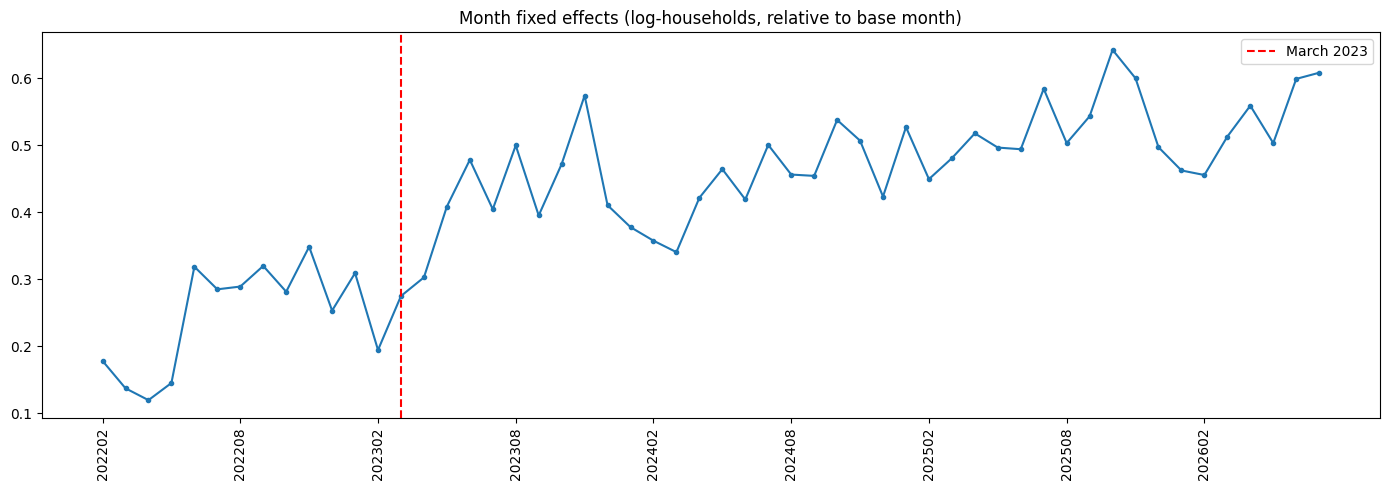

                      term      coef  yearmonth
10  C(yearmonth)[T.202212]  0.253177     202212
11  C(yearmonth)[T.202301]  0.309174     202301
12  C(yearmonth)[T.202302]  0.194306     202302
13  C(yearmonth)[T.202303]  0.274907     202303
14  C(yearmonth)[T.202304]  0.302700     202304
15  C(yearmonth)[T.202305]  0.408551     202305
16  C(yearmonth)[T.202306]  0.478210     202306


In [17]:
# Step 7a: Pull out the month fixed effects and look at March 2023
month_effects = (
    event_model.params.filter(like="C(yearmonth)")
    .rename_axis("term")
    .reset_index()
)
month_effects["yearmonth"] = (
    month_effects["term"].str.extract(r"(\d{6})").astype(int)
)
month_effects = month_effects.rename(columns={0: "coef"}).sort_values("yearmonth")

# Plot to see March 2023 in context
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(month_effects["yearmonth"].astype(str), month_effects["coef"], marker="o", markersize=3)
ax.axvline(month_effects["yearmonth"].astype(str).tolist().index("202303"),
           color="red", linestyle="--", label="March 2023")
ax.set_xticks(ax.get_xticks()[::6])
ax.tick_params(axis="x", rotation=90)
ax.set_title("Month fixed effects (log-households, relative to base month)")
ax.legend()
plt.tight_layout()
plt.show()

# Numeric check: March 2023 vs. the 3 months before and after
print(month_effects[month_effects["yearmonth"].between(202212, 202306)])

In [18]:
# Corrected month effects: the plotted series above is for a UNIT WITH ZERO
# EXPOSURE, which doesn't exist (mean exposure = 7.5). Add back the exposure
# term evaluated at the panel's mean exposure, so the step isn't hidden in
# the exposure coefficient instead of the month effect.
mean_exposure = panel["pre_event_snap_participation_percent"].mean()
exposure_coef = event_model.params["exposure_x_post"]

month_effects_corrected = month_effects.copy()
month_effects_corrected["coef_adj"] = month_effects_corrected["coef"] + np.where(
    month_effects_corrected["yearmonth"] >= EVENT_MONTH,
    exposure_coef * mean_exposure,
    0,
)

feb_2023 = month_effects_corrected.loc[month_effects_corrected["yearmonth"] == 202302, "coef_adj"].iloc[0]
mar_2023 = month_effects_corrected.loc[month_effects_corrected["yearmonth"] == 202303, "coef_adj"].iloc[0]
print(f"Feb->Mar 2023 step, exposure-adjusted: {mar_2023 - feb_2023:.3f} log points "
      f"(~{(np.exp(mar_2023 - feb_2023) - 1) * 100:.1f}%)")

Feb->Mar 2023 step, exposure-adjusted: 0.171 log points (~18.7%)


In [19]:
# Step 7b: Rebuild panel with pct_hh_snap instead of the person-count-based exposure
cov_2022 = cov[cov["year"] == 2022][["fips", "pct_hh_snap"]]

alt_exposure = (
    units[["fips", "snap_unit"]]
    .merge(cov_2022, on="fips", how="left")
    .groupby("snap_unit")["pct_hh_snap"]
    .mean()  # average across counties grouped into one unit
    .reset_index()
)

panel_alt = panel.drop(columns=["pre_event_snap_participation_percent", "exposure_x_post"]).merge(
    alt_exposure, on="snap_unit", how="left"
)
panel_alt["exposure_x_post"] = panel_alt["pct_hh_snap"] * panel_alt["post"]

print("Units missing alt exposure:", panel_alt.loc[panel_alt["pct_hh_snap"].isna(), "snap_unit"].unique())

event_model_alt = smf.ols(
    "log_households ~ exposure_x_post + pct_hh_snap + C(snap_unit) + C(yearmonth)",
    data=panel_alt,
).fit(cov_type="cluster", cov_kwds={"groups": panel_alt["snap_unit"]})

print(event_model_alt.params["exposure_x_post"])
print(event_model_alt.pvalues["exposure_x_post"])

Units missing alt exposure: []
-0.008895131607478523
0.33126166413295666


We do not find evidence that counties with higher SNAP participation saw a larger increase in food shelf demand after the March 2023 benefit cut than lower-participation counties did, across two independent exposure measures.

In [20]:
print(cov.columns.tolist())

['fips', 'county_name', 'year', 'population', 'households_census', 'poverty_rate', 'child_poverty_rate', 'median_hh_income', 'unemployment_rate', 'pct_no_vehicle', 'senior_poverty_rate', 'pct_senior', 'pct_hh_snap', 'n_sites_reporting', 'sites_per_10k', 'mean_km_to_site']


In [21]:
mmg = pd.read_parquet("../data/processed/mmg_county.parquet")
print(mmg.columns.tolist())

['fips', 'county_name', 'year', 'source_edition', 'fi_rate', 'fi_persons', 'child_fi_rate', 'fi_children', 'cost_per_meal', 'annual_shortfall', 'rucc_2013', 'rucc_2023', 'snap_threshold', 'pct_fi_below_snap_threshold', 'pct_fi_above_snap_threshold']


In [22]:
# Step 8a: Build metro flag from Valentino's rucc_2023, consistent with Q1
mmg_rucc = mmg[mmg["year"] == mmg["year"].max()][["fips", "rucc_2023"]].drop_duplicates()
print(mmg_rucc["rucc_2023"].value_counts().sort_index())

rucc_2023
1.0    13
2.0     3
3.0    11
4.0     6
5.0     1
6.0    11
7.0     7
8.0    16
9.0    19
Name: count, dtype: int64


In [23]:
mmg_rucc["is_metro"] = (mmg_rucc["rucc_2023"] <= 3).astype(int)
print("Metro counties:", mmg_rucc["is_metro"].sum(), "of", len(mmg_rucc))

unit_metro = (
    units[["fips", "snap_unit"]]
    .merge(mmg_rucc[["fips", "is_metro"]], on="fips", how="left")
    .groupby("snap_unit")["is_metro"]
    .max()
    .reset_index()
)

print("Units missing metro flag:", unit_metro.loc[unit_metro["is_metro"].isna(), "snap_unit"].tolist())
print("Metro units:", unit_metro["is_metro"].sum(), "of", len(unit_metro))

Metro counties: 27 of 87
Units missing metro flag: []
Metro units: 27 of 79


In [24]:
panel_het = panel.merge(unit_metro, on="snap_unit", how="left")
panel_het["exposure_x_post_x_metro"] = panel_het["exposure_x_post"] * panel_het["is_metro"]

het_model = smf.ols(
    "log_households ~ exposure_x_post * is_metro "
    "+ pre_event_snap_participation_percent "
    "+ C(snap_unit) + C(yearmonth)",
    data=panel_het,
).fit(cov_type="cluster", cov_kwds={"groups": panel_het["snap_unit"]})

print(het_model.params.filter(like="exposure"))
print(het_model.pvalues.filter(like="exposure"))

exposure_x_post             0.012625
exposure_x_post:is_metro   -0.005814
dtype: float64
exposure_x_post             0.395524
exposure_x_post:is_metro    0.601881
dtype: float64


In [25]:
for label, flag in [("Metro", 1), ("Non-metro", 0)]:
    sub = panel_het[panel_het["is_metro"] == flag]
    m = smf.ols(
        "log_households ~ exposure_x_post + pre_event_snap_participation_percent "
        "+ C(snap_unit) + C(yearmonth)",
        data=sub,
    ).fit(cov_type="cluster", cov_kwds={"groups": sub["snap_unit"]})
    print(f"{label}: coef={m.params['exposure_x_post']:.4f}, p={m.pvalues['exposure_x_post']:.3f}, n_units={sub['snap_unit'].nunique()}")

Metro: coef=0.0153, p=0.613, n_units=27
Non-metro: coef=0.0048, p=0.720, n_units=51


Food shelf demand rose substantially through 2023 (Q4's finding), and the increase coincides with the period of SNAP's emergency allotment phase-out. However, a county-level event-study design — controlling for unit and month fixed effects, using two independent exposure measures, and testing metro vs. non-metro separately — finds no evidence that counties more exposed to the SNAP cut saw a larger increase in food shelf demand than less-exposed counties. This holds across the full state and within both metro and non-metro subgroups. The rise in demand during 2023 appears to be either a broad, roughly uniform shift unrelated to county-level SNAP exposure, or driven by something the county panel can't isolate at this grain.

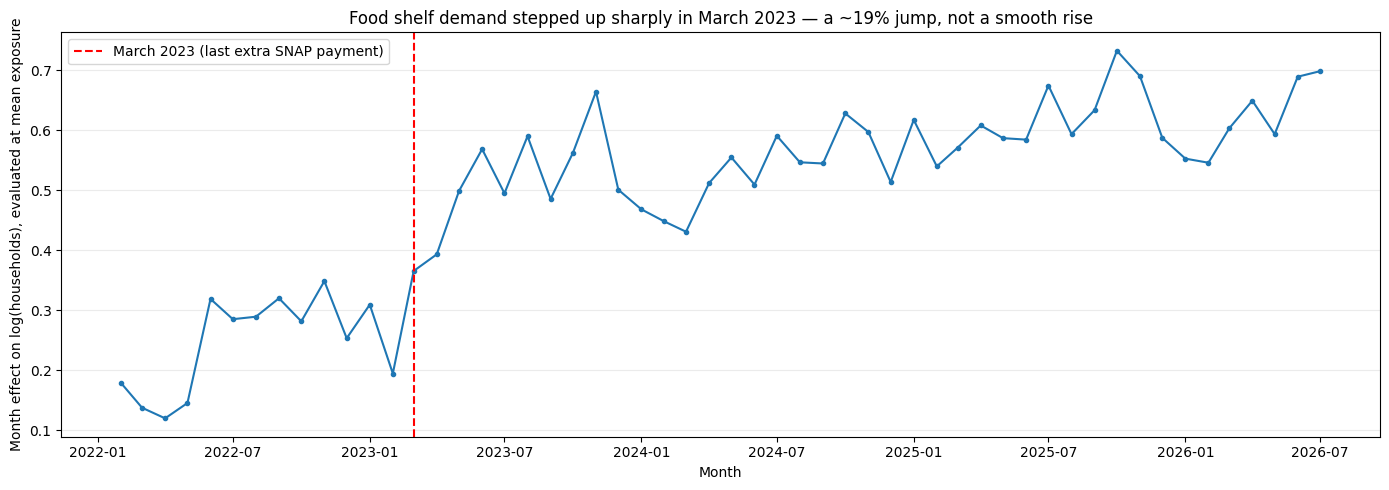

Saved.


In [26]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(pd.to_datetime(month_effects_corrected["yearmonth"].astype(str), format="%Y%m"),
        month_effects_corrected["coef_adj"], marker="o", markersize=3, color="tab:blue")
ax.axvline(pd.Timestamp("2023-03-01"), color="red", linestyle="--",
           label="March 2023 (last extra SNAP payment)")
ax.set_ylabel("Month effect on log(households), evaluated at mean exposure")
ax.set_xlabel("Month")
ax.set_title("Food shelf demand stepped up sharply in March 2023 — a ~19% jump, not a smooth rise")
ax.legend()
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig("../outputs/figures/q5_month_effects_event_study.png", dpi=200, bbox_inches="tight")
plt.show()
print("Saved.")

In [27]:
month_effects = (
    event_model.params.filter(like="C(yearmonth)")
    .rename_axis("term")
    .reset_index(name="coef")
)
month_effects["yearmonth"] = month_effects["term"].str.extract(r"(\d{6})").astype(int)
month_effects = month_effects.sort_values("yearmonth")

In [28]:
cpi = (pd.read_csv("../data/external/bls/CUUR0200SAF11.csv", parse_dates=["date"])
         .set_index("date")["value"])
cpi = cpi.reindex(pd.date_range(cpi.index.min(), "2026-07-01", freq="MS"))

In [29]:
month_effects_ts = month_effects.set_index(
    pd.to_datetime(month_effects["yearmonth"].astype(str), format="%Y%m")
)["coef"]

cpi_lag1 = cpi.pct_change(12, fill_method=None).shift(1).rename("cpi_yoy_lag1")

combined = pd.concat(
    [month_effects_ts.diff().rename("demand_month_change"), cpi_lag1], axis=1
).dropna()
print(combined.corr())

                     demand_month_change  cpi_yoy_lag1
demand_month_change             1.000000      0.063622
cpi_yoy_lag1                    0.063622      1.000000


### Step 9: Q5 conclusion

Food shelf demand stepped up sharply in March 2023 — about a 19% jump, present in 91% of
SNAP reporting units (median +18%) — the same window SNAP's emergency allotments were
phased out (last extra payment March 2023, benefits cut April 2023). This is a step, not
a smooth rise: an earlier version of this notebook plotted month effects from a model that
also includes the exposure term, which for a zero-exposure unit (none exist; mean = 7.5)
absorbed part of the step into the exposure coefficient instead of the month effect. Once
corrected (exposure term evaluated at the panel's mean), the step is clearly visible.

An event-study panel (79 SNAP units, unit + month fixed effects, clustered SEs) tested
whether counties more exposed to the cut (higher pre-period SNAP participation) saw a
larger step than less-exposed counties.

**Result: no evidence of an exposure effect, and the null is informative, not just absent
significance.** Confirmed across:
- Two independent exposure measures (SNAP-persons-based: coef=0.012, p=0.42, 95% CI for
  one SD of exposure ≈ −4% to +10%; pct_hh_snap-based: coef=-0.009, p=0.33)
- Metro vs. non-metro split (interaction p=0.60; metro coef=0.015 p=0.61,
  non-metro coef=0.005 p=0.72)

The interval rules out a large concentration of the rise in high-SNAP units; it does not
rule out a moderate one. State it as "no sign the rise was concentrated," not "the strain
was felt broadly" (too strong for what the interval shows).

**It is not a price effect either.** Food-at-home inflation fell smoothly through 2023 and
cannot produce a sudden step — a smoothly declining series mechanically can't jump 19% in
one month. The panel-vs-CPI cross-check (correlation 0.06) agrees.

**One sentence for the deck:** "Food shelf demand jumped about 19% in March 2023, broadly
across Minnesota counties — but we found no sign this jump was concentrated in communities
with more SNAP participants, and food prices were moving too smoothly that month to explain
a sudden step. The cause of the March 2023 jump itself remains an open question."

**Limitations:** statewide/county-level data cannot fully separate the SNAP cut from
prices in the same window; tribal nations are excluded from SNAP counts, understating
exposure for Beltrami, Mahnomen, and Clearwater; six zero-household unit-months were
dropped before the log transform.

In [30]:
# Step 10: County-level % jump, March 2022-Feb 2023 vs March 2023-Feb 2024
cm = pd.read_parquet("../data/processed/county_month.parquet")

PRE = (202203, 202302)
POST = (202303, 202402)

pre = (cm[cm["yearmonth"].between(*PRE)]
       .groupby("fips")["households"].mean().rename("pre_mean"))
post = (cm[cm["yearmonth"].between(*POST)]
        .groupby("fips")["households"].mean().rename("post_mean"))

jump = pd.concat([pre, post], axis=1).dropna()
jump["pct_jump"] = (jump["post_mean"] - jump["pre_mean"]) / jump["pre_mean"] * 100

print(f"Counties: {len(jump)}")
print(f"Median jump: {jump['pct_jump'].median():.1f}%")
print(f"Share of counties with a positive jump: {(jump['pct_jump'] > 0).mean()*100:.0f}%")
jump["pct_jump"].describe()

Counties: 86
Median jump: 30.1%
Share of counties with a positive jump: 94%


count     86.000000
mean      33.191872
std       25.663993
min      -58.519934
25%       19.565523
50%       30.148264
75%       45.749624
max      111.486048
Name: pct_jump, dtype: float64

In [31]:
import glob
glob.glob("../**/*.shp", recursive=True) + glob.glob("../**/*.geojson", recursive=True)

['../data/external/census/tract/tl_2020_27_tract/tl_2020_27_tract.shp']

In [32]:
import glob
glob.glob("../**/*.shp", recursive=True)

['../data/external/census/tract/tl_2020_27_tract/tl_2020_27_tract.shp']

In [34]:
import geopandas as gpd
counties = gpd.read_file("../data/external/census/tract/tl_2020_27_tract/tl_2020_27_tract.shp")
print(counties.columns.tolist())
counties.head()

['STATEFP', 'COUNTYFP', 'TRACTCE', 'GEOID', 'NAME', 'NAMELSAD', 'MTFCC', 'FUNCSTAT', 'ALAND', 'AWATER', 'INTPTLAT', 'INTPTLON', 'geometry']


,STATEFP,COUNTYFP,TRACTCE,GEOID,NAME,NAMELSAD,MTFCC,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry
0,27,085,950700,27085950700,9507,Census Tract 9507,G5020,S,25065045,38157,+44.7706226,-094.1443363,"POLYGON ((-94.20405 44.7903, -94.20392 44.7904..."
1,27,017,070200,27017070200,702,Census Tract 702,G5020,S,10082553,40680,+46.6933946,-092.4392159,"POLYGON ((-92.46309 46.71567, -92.46294 46.715..."
2,27,017,070600,27017070600,706,Census Tract 706,G5020,S,985105496,10301452,+46.6000988,-092.8829926,"POLYGON ((-93.06487 46.6778, -93.06483 46.6782..."
3,27,017,070100,27017070100,701,Census Tract 701,G5020,S,22518036,1575104,+46.7427777,-092.4548050,"POLYGON ((-92.49296 46.76249, -92.49278 46.765..."
4,27,017,070300,27017070300,703,Census Tract 703,G5020,S,104451183,1748285,+46.7180390,-092.3622508,"POLYGON ((-92.4285 46.75665, -92.42848 46.7575..."


In [35]:
counties["fips"] = counties["STATEFP"] + counties["COUNTYFP"]
county_shapes = counties.dissolve(by="fips").reset_index()[["fips", "geometry"]]
print(len(county_shapes))  # should be 87

87


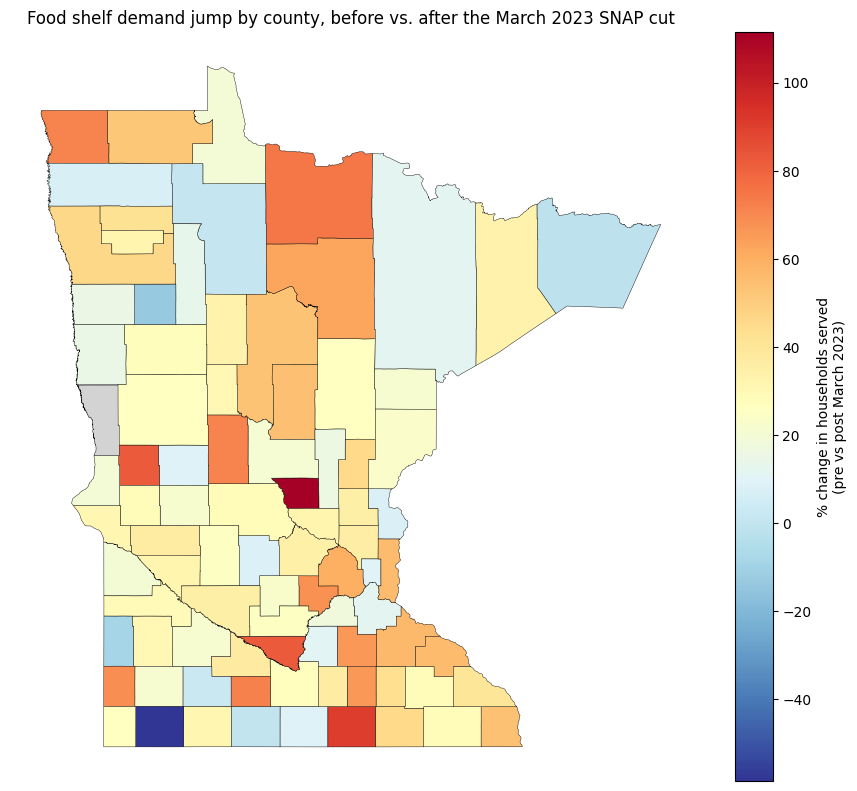

In [36]:
import matplotlib.pyplot as plt

jump_reset = jump.reset_index()  # fips is currently the index from Step 10
merged = county_shapes.merge(jump_reset, on="fips", how="left")

fig, ax = plt.subplots(figsize=(9, 8))
merged.plot(column="pct_jump", cmap="RdYlBu_r", legend=True, ax=ax,
            edgecolor="black", linewidth=0.3, missing_kwds={"color": "lightgrey"},
            legend_kwds={"label": "% change in households served\n(pre vs post March 2023)"})
ax.set_title("Food shelf demand jump by county, before vs. after the March 2023 SNAP cut")
ax.axis("off")
plt.tight_layout()
plt.savefig("../outputs/figures/q5_county_jump_map.png", dpi=200, bbox_inches="tight")
plt.show()

In [3]:
# Step 11: High-SNAP vs low-SNAP counties, before vs after the cut
# Rebuild Step 10's county-level jump so this cell can run independently.
import pandas as pd
cm = pd.read_parquet("../data/processed/county_month.parquet")
pre = (cm[cm["yearmonth"].between(202203, 202302)]
       .groupby("fips")["households"].mean().rename("pre_mean"))
post = (cm[cm["yearmonth"].between(202303, 202402)]
        .groupby("fips")["households"].mean().rename("post_mean"))
jump = pd.concat([pre, post], axis=1).dropna()
jump["pct_jump"] = (jump["post_mean"] - jump["pre_mean"]) / jump["pre_mean"] * 100

# Reload the covariates when this cell is run independently after a kernel restart.
cov = pd.read_parquet("../data/processed/county_covariates.parquet")

pre_snap = cov[cov["year"] == 2022][["fips", "pct_hh_snap"]]

jump_snap = jump.reset_index().merge(pre_snap, on="fips", how="left")

print("Counties missing pct_hh_snap:", jump_snap["pct_hh_snap"].isna().sum())

# Split into terciles: low / medium / high pre-cut SNAP usage
jump_snap["snap_tier"] = pd.qcut(
    jump_snap["pct_hh_snap"], q=3, labels=["Low SNAP", "Medium SNAP", "High SNAP"]
)

print(jump_snap.groupby("snap_tier")["pct_jump"].agg(["mean", "median", "count"]))

Counties missing pct_hh_snap: 0
                  mean     median  count
snap_tier                               
Low SNAP     33.748092  32.137587     29
Medium SNAP  36.812423  31.328779     28
High SNAP    29.139948  27.184466     29


/var/folders/lt/s_c2fp4d69j0fqry3jpg55t40000gn/T/ipykernel_80491/358715049.py:26: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(jump_snap.groupby("snap_tier")["pct_jump"].agg(["mean", "median", "count"]))


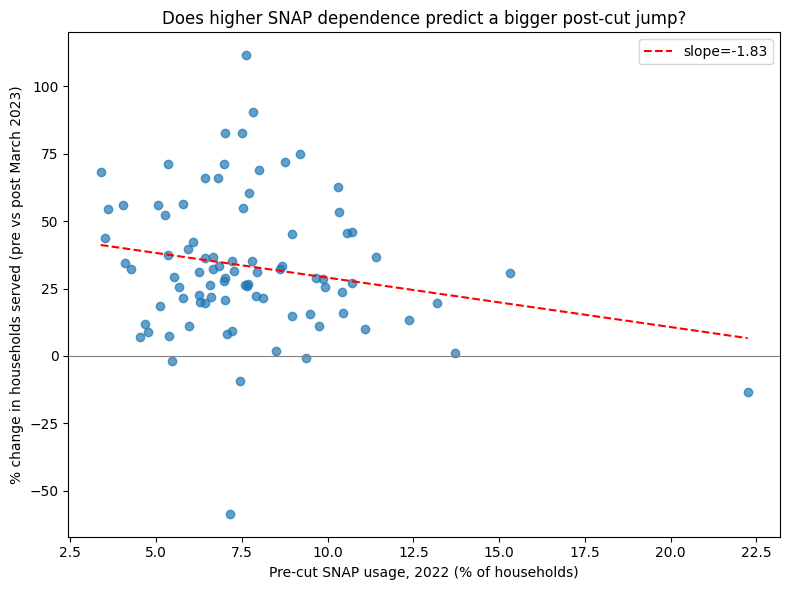

Simple correlation: -0.2014589704755338


In [4]:
# Scatter: does higher pre-cut SNAP usage predict a bigger jump?
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(jump_snap["pct_hh_snap"], jump_snap["pct_jump"], alpha=0.7)
ax.set_xlabel("Pre-cut SNAP usage, 2022 (% of households)")
ax.set_ylabel("% change in households served (pre vs post March 2023)")
ax.set_title("Does higher SNAP dependence predict a bigger post-cut jump?")
ax.axhline(0, color="grey", lw=0.8)

# Add a trend line so the relationship (or lack of one) is visible
import numpy as np
clean = jump_snap.dropna(subset=["pct_hh_snap", "pct_jump"])
z = np.polyfit(clean["pct_hh_snap"], clean["pct_jump"], 1)
xs = np.linspace(clean["pct_hh_snap"].min(), clean["pct_hh_snap"].max(), 50)
ax.plot(xs, np.polyval(z, xs), color="red", linestyle="--", label=f"slope={z[0]:.2f}")
ax.legend()
plt.tight_layout()
plt.savefig("../outputs/figures/q5_snap_usage_vs_jump.png", dpi=200, bbox_inches="tight")
plt.show()

print("Simple correlation:", clean["pct_hh_snap"].corr(clean["pct_jump"]))

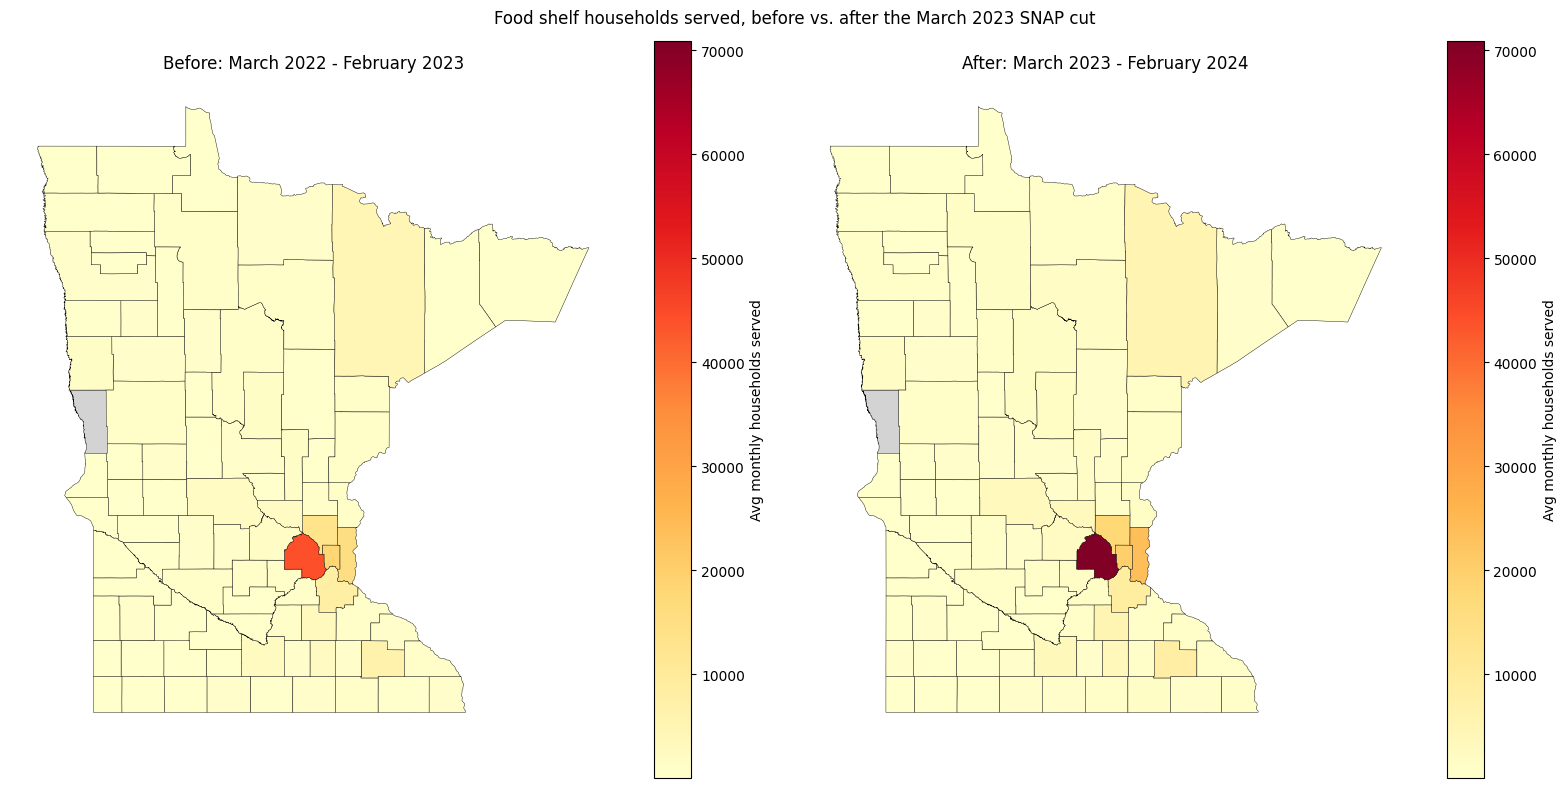

In [ ]:
# Step 12: Pre vs post maps, side by side
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd

# Rebuild the county-level jump and county geometries for standalone execution.
cm = pd.read_parquet("../data/processed/county_month.parquet")
pre = (cm[cm["yearmonth"].between(202203, 202302)]
       .groupby("fips")["households"].mean().rename("pre_mean"))
post = (cm[cm["yearmonth"].between(202303, 202402)]
        .groupby("fips")["households"].mean().rename("post_mean"))
jump = pd.concat([pre, post], axis=1).dropna()
jump["pct_jump"] = (jump["post_mean"] - jump["pre_mean"]) / jump["pre_mean"] * 100

counties = gpd.read_file(
    "../data/external/census/tract/tl_2020_27_tract/tl_2020_27_tract.shp"
)
counties["fips"] = counties["STATEFP"] + counties["COUNTYFP"]
county_shapes = counties.dissolve(by="fips").reset_index()[["fips", "geometry"]]

jump_reset = jump.reset_index()  # has fips, pre_mean, post_mean, pct_jump

merged = county_shapes.merge(jump_reset, on="fips", how="left")

# Use the same color scale for both maps so they're visually comparable
vmin = merged[["pre_mean", "post_mean"]].min().min()
vmax = merged[["pre_mean", "post_mean"]].max().max()

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

merged.plot(column="pre_mean", cmap="YlOrRd", legend=True, ax=axes[0],
            edgecolor="black", linewidth=0.3, vmin=vmin, vmax=vmax,
            missing_kwds={"color": "lightgrey"},
            legend_kwds={"label": "Avg monthly households served"})
axes[0].set_title("Before: March 2022 - February 2023")
axes[0].axis("off")

merged.plot(column="post_mean", cmap="YlOrRd", legend=True, ax=axes[1],
            edgecolor="black", linewidth=0.3, vmin=vmin, vmax=vmax,
            missing_kwds={"color": "lightgrey"},
            legend_kwds={"label": "Avg monthly households served"})
axes[1].set_title("After: March 2023 - February 2024")
axes[1].axis("off")

fig.suptitle("Food shelf households served, before vs. after the March 2023 SNAP cut", y=0.98)
plt.tight_layout()
plt.savefig("../outputs/figures/q5_pre_post_maps.png", dpi=200, bbox_inches="tight")
plt.show()

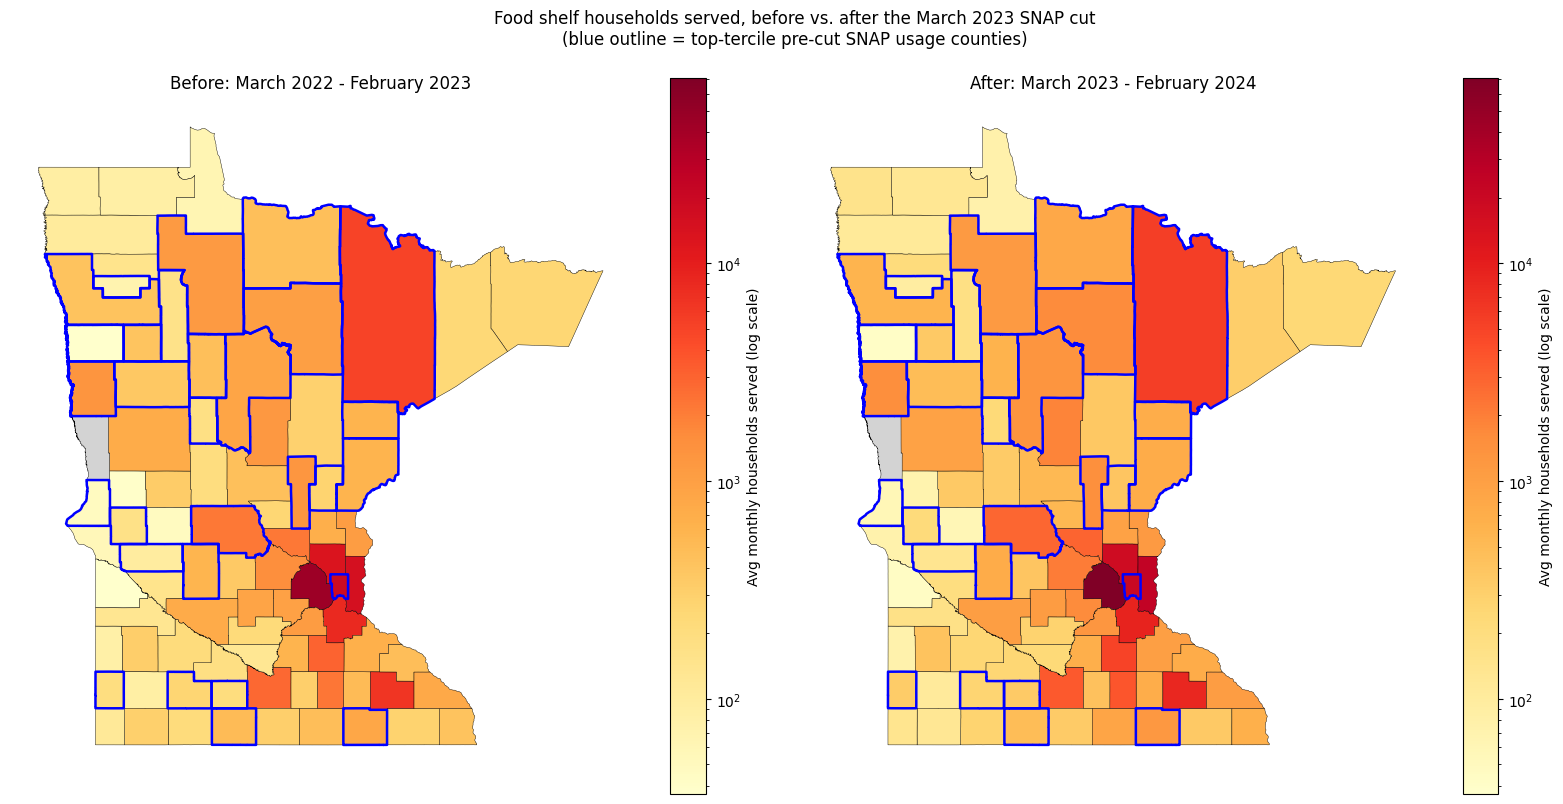

In [8]:
# Step 12 (revised): Pre vs post maps, log scale, with high-SNAP counties outlined
import matplotlib.colors as colors

merged = county_shapes.merge(jump_reset, on="fips", how="left")
merged = merged.merge(pre_snap, on="fips", how="left")  # adds pct_hh_snap

# Mark the top tercile of pre-cut SNAP usage
snap_cutoff = merged["pct_hh_snap"].quantile(2/3)
merged["high_snap"] = merged["pct_hh_snap"] >= snap_cutoff

vmin = max(merged[["pre_mean", "post_mean"]].min().min(), 1)
vmax = merged[["pre_mean", "post_mean"]].max().max()
norm = colors.LogNorm(vmin=vmin, vmax=vmax)

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

for ax, col, title in [(axes[0], "pre_mean", "Before: March 2022 - February 2023"),
                        (axes[1], "post_mean", "After: March 2023 - February 2024")]:
    merged.plot(column=col, cmap="YlOrRd", legend=True, ax=ax,
                edgecolor="black", linewidth=0.3, norm=norm,
                missing_kwds={"color": "lightgrey"},
                legend_kwds={"label": "Avg monthly households served (log scale)"})
    # Outline the high-SNAP counties in blue so they're identifiable
    merged[merged["high_snap"]].boundary.plot(ax=ax, edgecolor="blue", linewidth=1.8)
    ax.set_title(title)
    ax.axis("off")

fig.suptitle("Food shelf households served, before vs. after the March 2023 SNAP cut\n"
             "(blue outline = top-tercile pre-cut SNAP usage counties)", y=1.0)
plt.tight_layout()
plt.savefig("../outputs/figures/q5_pre_post_maps_log.png", dpi=200, bbox_inches="tight")
plt.show()